# Assignment 2: t-SNE and UMAP 2D representations

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import umap

/Users/erkhesmunkhchuluun/miniforge3/envs/allensdk/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SESSION_ID = 757216464
data_dir = os.path.expanduser("~/allen_neuropixels_data/assignment2")

stim = pd.read_pickle(os.path.join(data_dir, f"{SESSION_ID}_stimulus.pkl"))
units = pd.read_pickle(os.path.join(data_dir, f"{SESSION_ID}_units.pkl"))
spikes = pd.read_pickle(os.path.join(data_dir, f"{SESSION_ID}_spikes.pkl"))

v1_units = units[units.ecephys_structure_acronym == "VISp"].index.values
print("V1 units:", len(v1_units))

counts = (
    spikes[spikes.unit_id.isin(v1_units)]
    .groupby(["stimulus_presentation_id", "unit_id"]).size()
    .unstack(fill_value=0)
    .reindex(index=stim.index, columns=v1_units, fill_value=0)
    .values
)  # trials x units

orientation = stim["orientation"].astype(float).values
print("counts shape:", counts.shape)

V1 units: 85
counts shape: (600, 85)


In [11]:
def plot_row(embs, titles, suptitle):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, emb, t in zip(axes, embs, titles):
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=orientation, cmap="twilight",
                        vmin=0, vmax=360, s=6)
        ax.set_title(t); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(sc, ax=axes, label="direction (deg)", shrink=0.8,
                 ticks=np.arange(0, 360, 45))
    fig.suptitle(suptitle)
    plt.show()

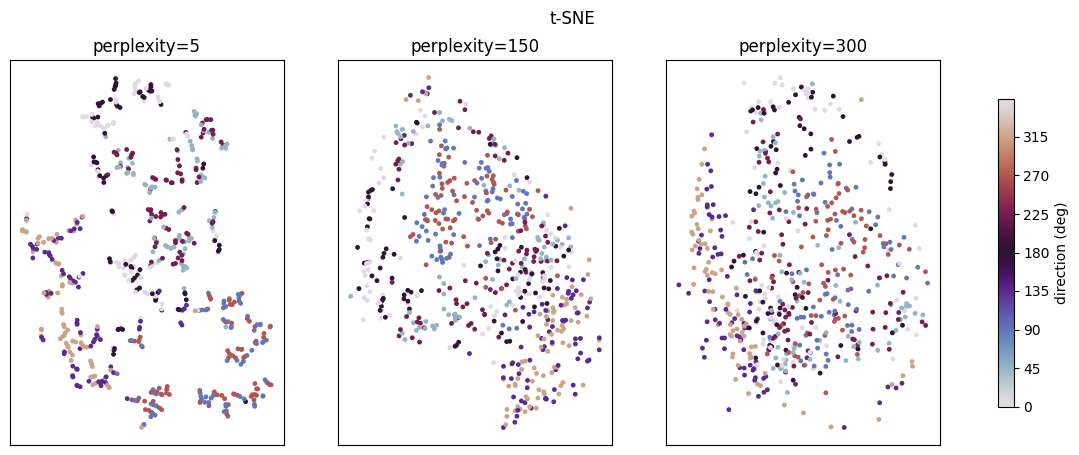

In [13]:
perplexities = [5, 150, 300]

tsne_embs, tsne_titles = [], []
for p in perplexities:
    tsne_embs.append(TSNE(n_components=2, perplexity=p, random_state=0).fit_transform(counts))
    tsne_titles.append(f"perplexity={p}")

plot_row(tsne_embs, tsne_titles, "t-SNE")

/Users/erkhesmunkhchuluun/miniforge3/envs/allensdk/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/erkhesmunkhchuluun/miniforge3/envs/allensdk/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/erkhesmunkhchuluun/miniforge3/envs/allensdk/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


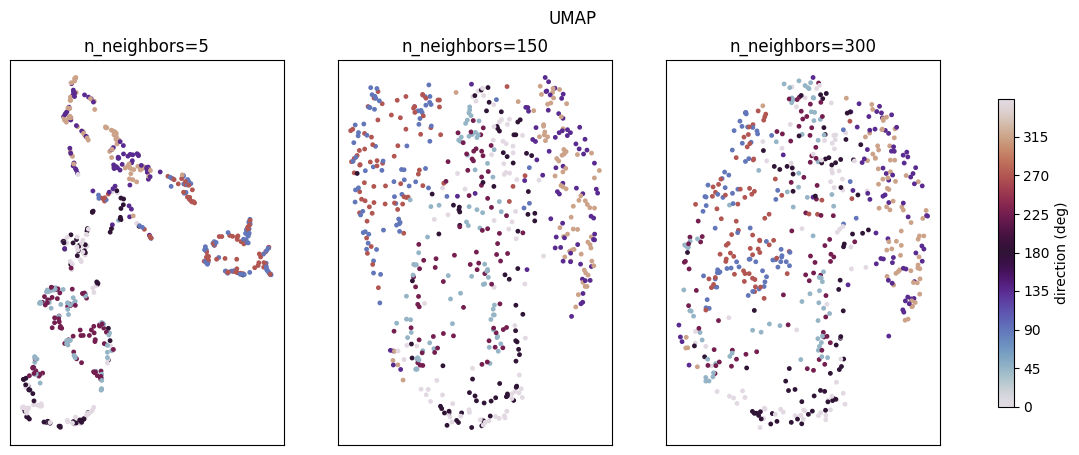

In [14]:
n_neighbors_list = [5, 150, 300]

umap_embs, umap_titles = [], []
for n in n_neighbors_list:
    umap_embs.append(umap.UMAP(n_components=2, n_neighbors=n, random_state=0).fit_transform(counts))
    umap_titles.append(f"n_neighbors={n}")

plot_row(umap_embs, umap_titles, "UMAP")